# Road Accident Analysis Using Exploratory Data Analysis (EDA)

## Project Objective

The objective of this project is to analyze road accident data and identify the factors that contribute to accident severity. Through data cleaning, feature engineering, visualization, and statistical analysis, the project aims to uncover meaningful patterns related to accident causes, weather conditions, alcohol involvement, vehicle types, and emergency response times.

## Dataset Overview

This dataset contains road accident records including accident details, driver information, environmental conditions, vehicle information, injury statistics, and accident severity levels.

The analysis follows the complete EDA process:
- Data Understanding
- Data Cleaning
- Missing Value Treatment
- Outlier Analysis
- Feature Engineering
- Univariate Analysis
- Bivariate Analysis
- Multivariate Analysis
- Correlation Analysis
- Key Findings and Recommendations

In [69]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
#from scipy.stats import chi2_contingency

# Global style
plt.style.use('seaborn-v0_8')
sns.set_palette('husl')
plt.rcParams.update({
    'figure.dpi': 100,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
})

In [70]:
import pandas as pd

# Load dataset
df = pd.read_csv("/content/road_accident_dataset_expanded.csv")

print(f"Dataset loaded: {df.shape[0]} rows × {df.shape[1]} columns")

Dataset loaded: 25375 rows × 24 columns


# Data Understanding

In this section, the structure of the dataset is examined to understand the available features, data types, and overall characteristics of the data.

The following checks are performed:
- Dataset shape
- Column names
- Data types
- Sample records
- Statistical summary

In [71]:
df.head()

,accident_id,date,time,state,city,road_type,weather_condition,light_condition,road_condition,cause,...,number_of_deaths,accident_severity,driver_age,driver_gender,alcohol_involved,driver_fatigue,helmet_used,seatbelt_used,traffic_density,emergency_response_time
0,1001,2018-05-02,08:20:00,Maharashtra,Solapur,Urban,Cloudy,Daylight,Fair,Speeding,...,0,Minor,24.0,Female,False,False,NaN,True,Low,25.0
1,1002,2022-07-30,09:00:00,Uttar Pradesh,Meerut,Rural,Rainy,Daylight,Wet,Signal Jumping,...,2,Moderate,63.0,Male,False,False,NaN,NaN,Low,50.0
2,1003,2019-10-20,22:24:00,Telangana,Warangal,Rural,Cloudy,Night,Good,Speeding,...,0,Moderate,47.0,Male,True,True,NaN,NaN,High,30.0
3,1004,2018-06-21,16:39:00,Madhya Pradesh,Ujjain,Rural,Rainy,Daylight,Wet,Vehicle Failure,...,0,Moderate,38.0,Male,False,False,NaN,False,Medium,38.0
4,1005,2021-07-04,13:04:00,Andhra Pradesh,Kurnool,Urban,Rainy,Daylight,Wet,Driver Fatigue,...,1,Moderate,46.0,NaN,False,True,NaN,True,High,12.0


In [72]:
df.shape

(25375, 24)

### The dataset has 25375 rows and 24 columns

In [73]:
df.describe()

,accident_id,speed_limit,number_of_vehicles,number_of_injuries,number_of_deaths,driver_age,emergency_response_time
count,25375.000000,24866.000000,24994.000000,25375.000000,25375.000000,24615.000000,24488.000000
mean,13688.000000,54.311510,2.316156,2.606345,0.558778,43.748040,27.245957
std,7325.275876,14.227282,1.247728,2.064850,0.834686,16.271521,14.993697
min,1001.000000,30.000000,1.000000,1.000000,0.000000,18.000000,12.000000
25%,7344.500000,40.000000,1.000000,1.000000,0.000000,30.000000,15.000000
50%,13688.000000,60.000000,2.000000,2.000000,0.000000,43.000000,30.000000
75%,20031.500000,60.000000,3.000000,3.000000,1.000000,55.000000,34.000000
max,26375.000000,160.000000,6.000000,34.000000,8.000000,79.000000,179.000000


In [74]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25375 entries, 0 to 25374
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   accident_id              25375 non-null  int64  
 1   date                     25375 non-null  object 
 2   time                     25375 non-null  object 
 3   state                    25375 non-null  object 
 4   city                     25375 non-null  object 
 5   road_type                25375 non-null  object 
 6   weather_condition        24740 non-null  object 
 7   light_condition          25375 non-null  object 
 8   road_condition           24863 non-null  object 
 9   cause                    24990 non-null  object 
 10  vehicle_type             25375 non-null  object 
 11  speed_limit              24866 non-null  float64
 12  number_of_vehicles       24994 non-null  float64
 13  number_of_injuries       25375 non-null  int64  
 14  number_of_deaths      

In [75]:
df.accident_severity.unique()

array(['Minor', 'Moderate', 'Serious', 'Fatal'], dtype=object)

# Data Type Conversion

After understanding the dataset structure, the data types of all columns were examined.

The `date` column was originally stored as an object data type. To enable time-based analysis and feature engineering, it was converted into a datetime format.

This conversion allows extraction of useful temporal features such as:
- Day of Week
- Month
- Year
- Weekend Indicator

In [76]:
df.date = pd.to_datetime(df.date)

# Missing Value Analysis

Missing values can affect the quality and reliability of analysis. Therefore, the dataset was examined to identify columns containing missing values and measure the extent of missing data.

The following steps were performed:
- Count missing values in each column
- Calculate percentage of missing values
- Visualize missing value distribution
- Identify columns requiring treatment

In [77]:
df.isna().sum()

,0
accident_id,0
date,0
time,0
state,0
city,0
road_type,0
weather_condition,635
light_condition,0
road_condition,512
cause,385


In [78]:
df.isna().mean()*100

,0
accident_id,0.000000
date,0.000000
time,0.000000
state,0.000000
city,0.000000
road_type,0.000000
weather_condition,2.502463
light_condition,0.000000
road_condition,2.017734
cause,1.517241


In [79]:
missing_values = df.isna().mean()*100

In [80]:
missing_values = missing_values[missing_values > 0]
missing_values

,0
weather_condition,2.502463
road_condition,2.017734
cause,1.517241
speed_limit,2.005911
number_of_vehicles,1.501478
driver_age,2.995074
driver_gender,1.990148
helmet_used,64.803941
seatbelt_used,46.865025
traffic_density,2.486700


In [81]:
from matplotlib import pyplot as plt

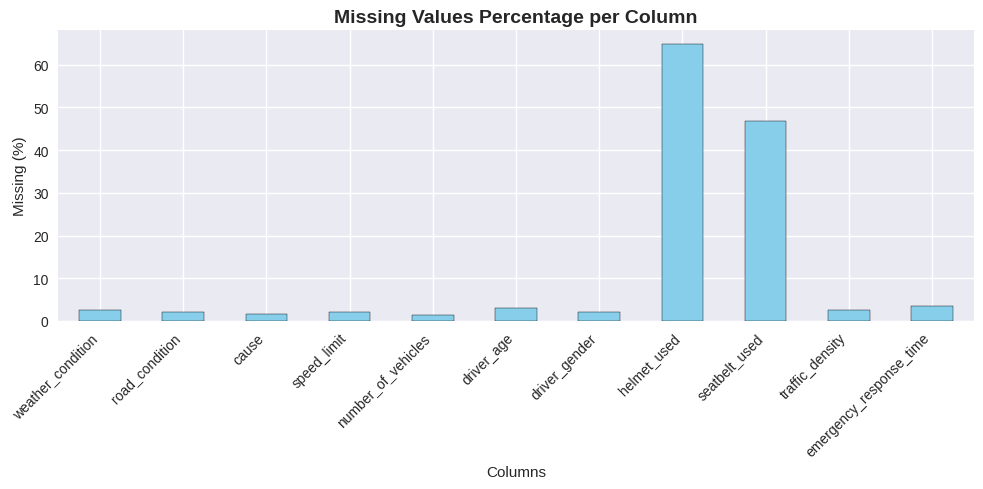

In [82]:
plt.figure(figsize=(10,5))
missing_values.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Missing Values Percentage per Column')
plt.xlabel('Columns')
plt.ylabel('Missing (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Observation

The majority of columns contained either no missing values or a very small percentage of missing values.

However, the following columns showed significant missingness:

- `helmet_used`
- `seatbelt_used`

This missingness was expected because certain vehicle types do not require helmets while others do not require seatbelts. Therefore, domain knowledge was used during data cleaning instead of blindly imputing values.

Other columns contained less than 5% missing values and were treated using appropriate statistical methods.

# Missing Value Treatment

After identifying missing values, a suitable treatment strategy was selected for each column based on data type and domain knowledge.

### Treatment Strategy

- Numerical columns were imputed using the median value to minimize the impact of outliers.
- Categorical columns were imputed using the mode (most frequent value).
- Helmet and seatbelt information required domain-specific treatment because their applicability depends on vehicle type.

Instead of blindly replacing missing values, relationships between vehicle type, helmet usage, and seatbelt usage were analyzed to ensure realistic data imputation.

In [83]:
df.helmet_used.unique()

array([nan, True, False], dtype=object)

In [84]:
df.helmet_used.value_counts()

,count
helmet_used,
True,5210
False,3721


In [85]:
df.seatbelt_used.unique()

array([True, nan, False], dtype=object)

In [86]:
df.seatbelt_used.value_counts()

,count
seatbelt_used,
True,8743
False,4740


In [87]:
df.vehicle_type.unique()

array(['Car', 'Auto-Rickshaw', 'Two-Wheeler', 'E-Bike', 'Truck', 'Bus',
       'Tempo', 'Cycle', 'SUV', 'Ambulance'], dtype=object)

## Domain-Based Analysis of Helmet and Seatbelt Usage

Helmet usage and seatbelt usage cannot be treated as ordinary missing values because their applicability depends on the vehicle involved in the accident.

For example:

- Two-Wheeler and E-Bike riders are expected to use helmets.
- Cars, SUVs, Trucks, Buses, and Ambulances require seatbelts rather than helmets.
- Cycles and Auto-Rickshaws generally do not use seatbelts.

Therefore, cross-tabulation between vehicle type and safety equipment usage was performed before imputing missing values.

In [88]:
helmet_relation = pd.crosstab(df.vehicle_type , df.helmet_used , dropna= False)
helmet_relation

helmet_used,False,True,NaN
vehicle_type,,,
Ambulance,0,0,137
Auto-Rickshaw,0,0,2056
Bus,0,0,2531
Car,0,0,6282
Cycle,0,0,513
E-Bike,0,0,392
SUV,0,0,1252
Tempo,0,0,731
Truck,0,0,2550


In [89]:
seatbelt_relation = pd.crosstab(df.vehicle_type , df.seatbelt_used , dropna= False)
seatbelt_relation

seatbelt_used,False,True,NaN
vehicle_type,,,
Ambulance,43,94,0
Auto-Rickshaw,0,0,2056
Bus,903,1628,0
Car,2212,4070,0
Cycle,0,0,513
E-Bike,0,0,392
SUV,414,838,0
Tempo,240,491,0
Truck,928,1622,0


In [90]:
not_applicable_helmet = ['Car','Truck','Auto-Rickshaw', 'Bus','Tempo', 'Cycle', 'SUV', 'Ambulance']

df.loc[(df.vehicle_type.isin(not_applicable_helmet)) & (df.helmet_used.isna()),'helmet_used'] = 'Not Applicable'

df.loc[(df.vehicle_type == 'E-Bike') & (df.helmet_used.isna()), 'helmet_used'] = 'Unknown'

In [91]:
df.helmet_used.value_counts(dropna= False)

,count
helmet_used,
Not Applicable,16052
True,5210
False,3721
Unknown,392


In [92]:
not_applicable_seatbelt = ['Auto-Rickshaw','Two-Wheeler','E-Bike','Cycle']

df.loc[(df.vehicle_type.isin(not_applicable_seatbelt)) & (df.seatbelt_used.isna()), 'seatbelt_used'] = 'Not Applicable'

In [93]:
df.seatbelt_used.value_counts(dropna= False)

,count
seatbelt_used,
Not Applicable,11892
True,8743
False,4740


### Observation

Missing values in helmet and seatbelt columns were handled using domain knowledge rather than statistical imputation.

- Vehicle types where helmets are not applicable were labeled as "Not Applicable".
- Vehicle types where seatbelts are not applicable were labeled as "Not Applicable".
- Missing helmet values for E-Bikes were retained as "Unknown" because no reliable assumption could be made.

This approach preserves the real-world meaning of the data and avoids introducing misleading information.

# Outlier Analysis

Outlier analysis was performed on numerical variables to identify unusually high or low values that may influence statistical analysis.

The following techniques were used:

- Histograms to understand data distribution.
- Box plots to identify potential outliers.

The numerical variables analyzed include:

- Speed Limit
- Number of Vehicles
- Driver Age
- Emergency Response Time

###  Categorical columns = weather_condition, road_condition, cause,driver_gender ,traffic_density               
### numerical columns = speed_limit, number_of_vehicles,driver_age ,emergency_response_time                     

                  
               
            
     

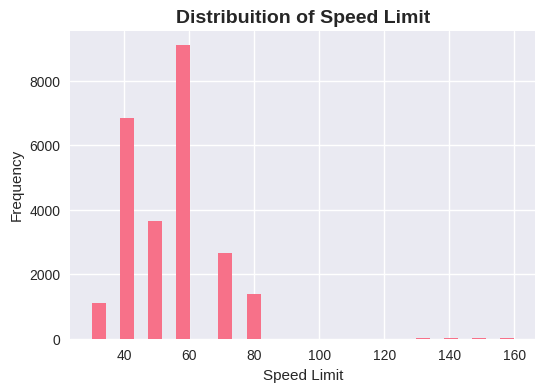

In [94]:
plt.figure(figsize = (6,4))
df.speed_limit.hist(bins= 30)
plt.title('Distribuition of Speed Limit')
plt.xlabel('Speed Limit')
plt.ylabel('Frequency')
plt.show()

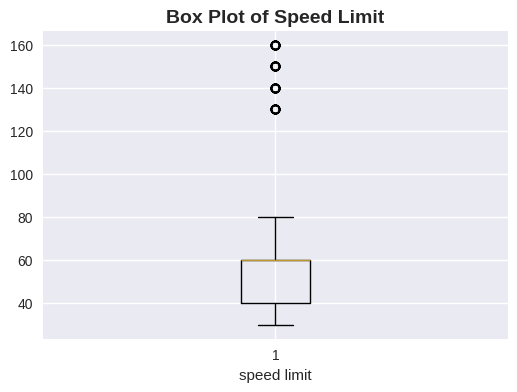

In [95]:
plt.figure(figsize=(6,4))
plt.boxplot(df.speed_limit.dropna())
plt.title('Box Plot of Speed Limit')
plt.xlabel('speed limit')
plt.show()

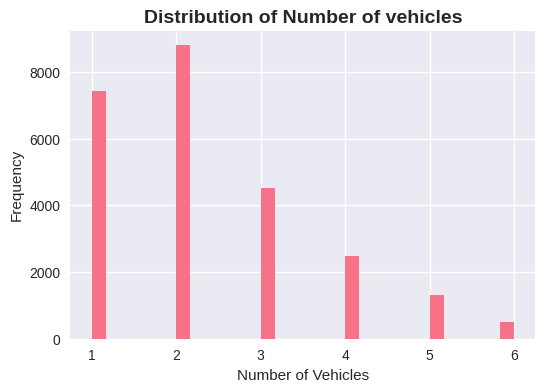

In [96]:
plt.figure(figsize = (6,4))
df.number_of_vehicles.hist(bins = 30)
plt.title("Distribution of Number of vehicles")
plt.xlabel('Number of Vehicles')
plt.ylabel('Frequency')
plt.show()

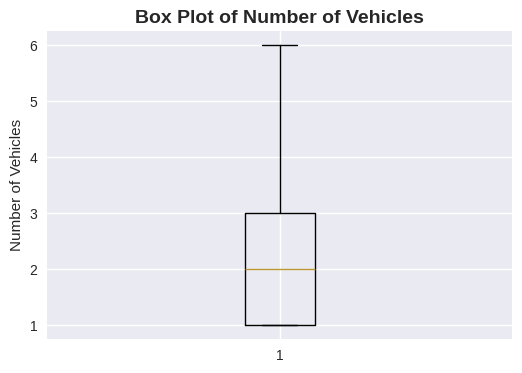

In [97]:
plt.figure(figsize=(6,4))
plt.boxplot(df.number_of_vehicles.dropna())
plt.title('Box Plot of Number of Vehicles')
plt.ylabel('Number of Vehicles')
plt.show()

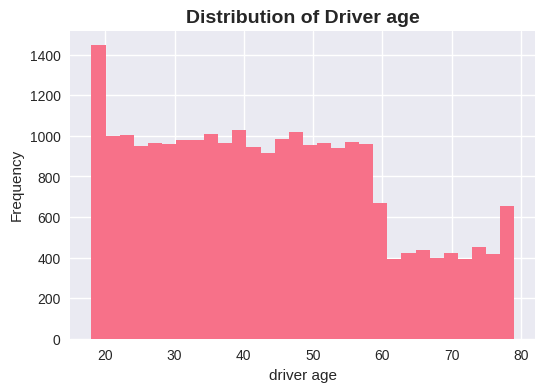

In [98]:
plt.figure(figsize = (6,4))
df.driver_age.hist(bins = 30)
plt.title("Distribution of Driver age")
plt.xlabel('driver age')
plt.ylabel('Frequency')
plt.show()

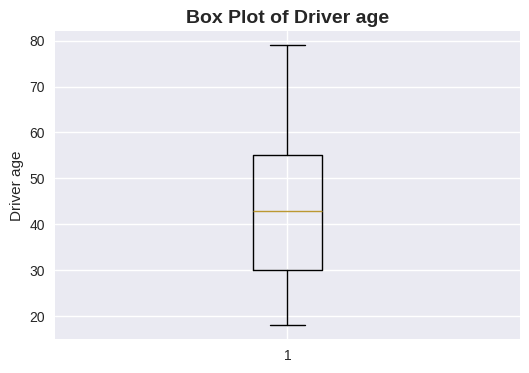

In [99]:
plt.figure(figsize=(6,4))
plt.boxplot(df.driver_age.dropna())
plt.title('Box Plot of Driver age')
plt.ylabel('Driver age')
plt.show()

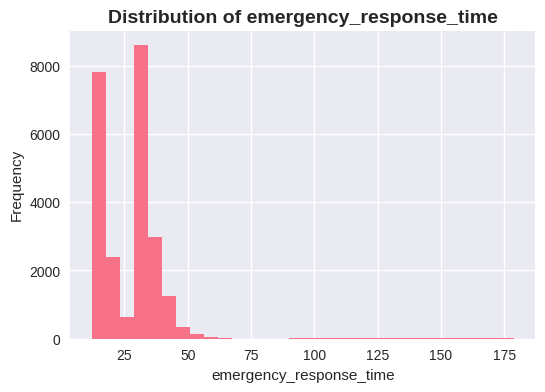

In [100]:
plt.figure(figsize = (6,4))
df.emergency_response_time.hist(bins = 30)
plt.title("Distribution of emergency_response_time")
plt.xlabel('emergency_response_time')
plt.ylabel('Frequency')
plt.show()

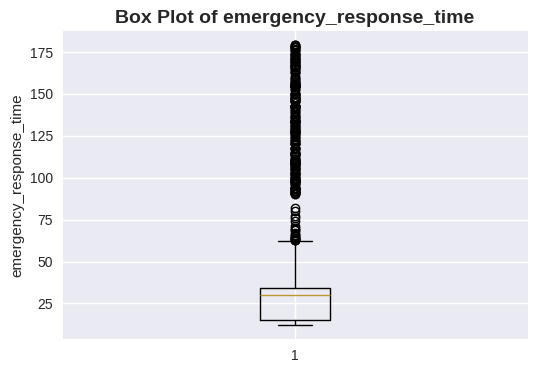

In [101]:
plt.figure(figsize=(6,4))
plt.boxplot(df.emergency_response_time.dropna())
plt.title('Box Plot of emergency_response_time')
plt.ylabel('emergency_response_time')
plt.show()

### Observation

The outlier analysis revealed the following:

- Speed Limit contained a small number of extreme values corresponding to high-speed roads and highways.
- Number of Vehicles showed no significant outliers.
- Driver Age exhibited a realistic distribution without abnormal observations.
- Emergency Response Time contained a substantial number of high values.

These observations were retained because they represent valid real-world scenarios rather than data entry errors.

For example, higher emergency response times may occur in remote locations, and higher speed limits may be associated with highways and expressways.

# Numerical Missing Value Imputation

Missing values in numerical columns were handled using median imputation.

Median was selected instead of mean because some variables contained outliers. The median is more robust to extreme values and preserves the overall distribution of the data.

The following columns were imputed using median values:

- Speed Limit
- Number of Vehicles
- Driver Age
- Emergency Response Time

In [102]:
df.speed_limit = df.speed_limit.fillna(df.speed_limit.median())
df.speed_limit.isna().sum()

np.int64(0)

In [103]:
df.number_of_vehicles = df.number_of_vehicles.fillna(df.number_of_vehicles.median())
df.number_of_vehicles.isna().sum()

np.int64(0)

In [104]:
df.driver_age = df.driver_age.fillna(df.driver_age.median())
df.driver_age.isna().sum()

np.int64(0)

In [105]:
df.emergency_response_time = df.emergency_response_time.fillna(df.emergency_response_time.median())
df.emergency_response_time.isna().sum()

np.int64(0)

# Categorical Missing Value Imputation

For categorical variables, missing values were replaced using the mode (most frequent category).

Mode imputation is suitable for categorical data because it preserves the existing distribution and avoids introducing artificial categories.

The following columns were treated using mode imputation:

- Weather Condition
- Road Condition
- Cause
- Driver Gender
- Traffic Density

In [106]:
df.weather_condition.value_counts()

,count
weather_condition,
Sunny,6177
Rainy,5848
Foggy,3631
Cloudy,2795
Haze,2700
Clear,2503
Stormy,1086


In [107]:
df.road_condition.value_counts()

,count
road_condition,
Wet,6367
Good,6203
Fair,5972
Poor,4677
Damaged,1013
Under_Repair,631


In [108]:
df.cause.value_counts()

,count
cause,
Speeding,5524
Drunk Driving,3779
Poor Road Conditions,3200
Driver Fatigue,3066
Distracted Driving,2457
Signal Jumping,1733
Tyre Burst,1431
Vehicle Failure,1262
Pedestrian Error,1029


In [109]:
df.driver_gender.value_counts()

,count
driver_gender,
Male,19388
Female,5223
Other,259


In [110]:
df.traffic_density.value_counts()

,count
traffic_density,
Medium,7485
High,7294
Low,6426
Very High,3539


In [111]:
df.weather_condition = df.weather_condition.fillna(df.weather_condition.mode()[0])
df.weather_condition.isna().sum()

np.int64(0)

In [112]:
df.road_condition = df.road_condition.fillna(df.road_condition.mode()[0])
df.road_condition.isna().sum()

np.int64(0)

In [113]:
df.cause = df.cause.fillna(df.cause.mode()[0])
df.cause.isna().sum()

np.int64(0)

In [114]:
df.driver_gender = df.driver_gender.fillna(df.driver_gender.mode()[0])
df.driver_gender.isna().sum()

np.int64(0)

In [115]:
df.traffic_density = df.traffic_density.fillna(df.traffic_density.mode()[0])
df.traffic_density.isna().sum()

np.int64(0)

# Verification of Missing Value Treatment

After applying the selected imputation techniques, a final verification was performed to ensure that all missing values had been successfully handled.

The dataset was checked again for missing values across all columns before proceeding to further analysis.

In [116]:
df.isna().sum()

,0
accident_id,0
date,0
time,0
state,0
city,0
road_type,0
weather_condition,0
light_condition,0
road_condition,0
cause,0


# Duplicate Value Analysis

Duplicate records can introduce bias and affect statistical analysis. Therefore, the dataset was examined for duplicate observations.

The duplicate check helps ensure data quality and prevents repeated records from influencing the results.

In [117]:
df.duplicated().sum()

np.int64(0)

In [118]:
df.columns

Index(['accident_id', 'date', 'time', 'state', 'city', 'road_type',
       'weather_condition', 'light_condition', 'road_condition', 'cause',
       'vehicle_type', 'speed_limit', 'number_of_vehicles',
       'number_of_injuries', 'number_of_deaths', 'accident_severity',
       'driver_age', 'driver_gender', 'alcohol_involved', 'driver_fatigue',
       'helmet_used', 'seatbelt_used', 'traffic_density',
       'emergency_response_time'],
      dtype='object')

In [119]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25375 entries, 0 to 25374
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   accident_id              25375 non-null  int64         
 1   date                     25375 non-null  datetime64[ns]
 2   time                     25375 non-null  object        
 3   state                    25375 non-null  object        
 4   city                     25375 non-null  object        
 5   road_type                25375 non-null  object        
 6   weather_condition        25375 non-null  object        
 7   light_condition          25375 non-null  object        
 8   road_condition           25375 non-null  object        
 9   cause                    25375 non-null  object        
 10  vehicle_type             25375 non-null  object        
 11  speed_limit              25375 non-null  float64       
 12  number_of_vehicles       25375 n

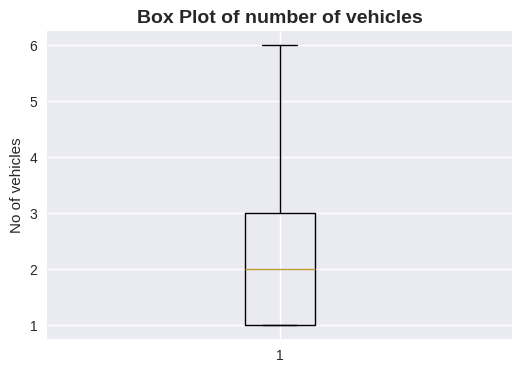

In [120]:
plt.figure(figsize=(6,4))
plt.boxplot(df.number_of_vehicles)
plt.title('Box Plot of number of vehicles')
plt.ylabel('No of vehicles')
plt.show()

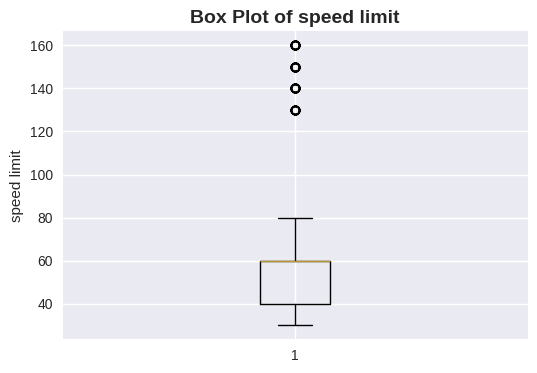

In [121]:
plt.figure(figsize=(6,4))
plt.boxplot(df.speed_limit)
plt.title('Box Plot of speed limit')
plt.ylabel('speed limit')
plt.show()

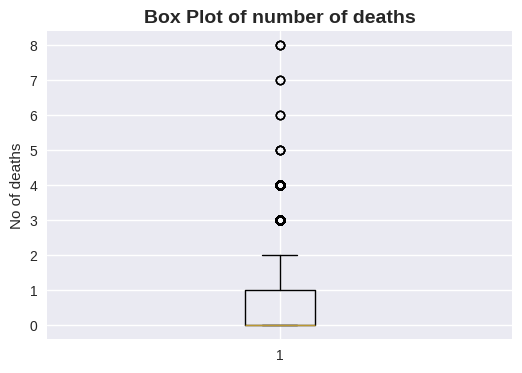

In [122]:
plt.figure(figsize=(6,4))
plt.boxplot(df.number_of_deaths)
plt.title('Box Plot of number of deaths')
plt.ylabel('No of deaths')
plt.show()

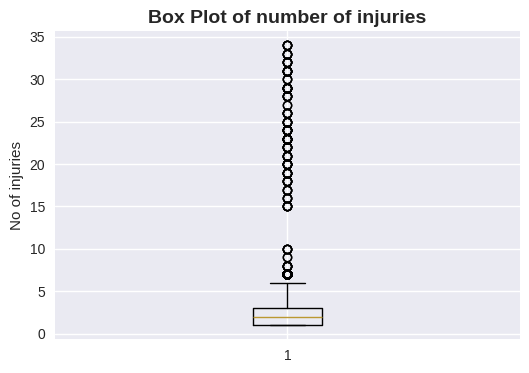

In [123]:
plt.figure(figsize=(6,4))
plt.boxplot(df.number_of_injuries)
plt.title('Box Plot of number of injuries')
plt.ylabel('No of injuries')
plt.show()

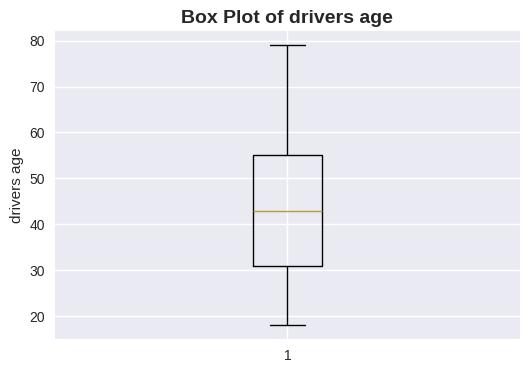

In [124]:
plt.figure(figsize=(6,4))
plt.boxplot(df.driver_age)
plt.title('Box Plot of drivers age')
plt.ylabel('drivers age')
plt.show()

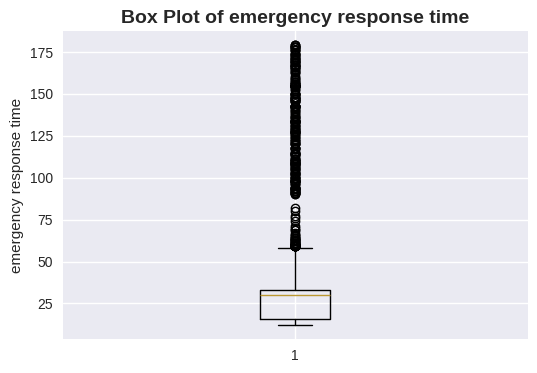

In [125]:
plt.figure(figsize=(6,4))
plt.boxplot(df.emergency_response_time)
plt.title('Box Plot of emergency response time')
plt.ylabel('emergency response time')
plt.show()

# Outlier Validation

Although outliers were identified in variables such as Speed Limit, Number of Injuries, Number of Deaths, and Emergency Response Time, they were not removed immediately.

Additional analysis was performed to determine whether these values represented genuine real-world observations or data quality issues.

The relationship between accident severity and numerical variables was examined to validate the significance of the detected outliers.

In [126]:
df.groupby('accident_severity')['speed_limit'].describe()

,count,mean,std,min,25%,50%,75%,max
accident_severity,,,,,,,,
Fatal,47.0,67.021277,22.928518,30.0,60.0,60.0,70.0,150.0
Minor,6801.0,52.151154,12.486632,30.0,40.0,50.0,60.0,150.0
Moderate,15630.0,54.751759,14.063162,30.0,40.0,60.0,60.0,160.0
Serious,2897.0,57.801174,16.584097,30.0,50.0,60.0,60.0,160.0


In [127]:
df.groupby('accident_severity')['emergency_response_time'].mean()

,emergency_response_time
accident_severity,
Fatal,29.425532
Minor,26.441553
Moderate,27.563724
Serious,28.227822


In [128]:
df.groupby('number_of_deaths')['emergency_response_time'].mean()

,emergency_response_time
number_of_deaths,
0,27.124469
1,27.591943
2,27.806552
3,28.270169
4,27.643192
5,23.200000
6,34.666667
7,26.333333
8,30.750000


In [129]:
df.groupby('accident_severity')['number_of_injuries'].mean()

,number_of_injuries
accident_severity,
Fatal,6.446809
Minor,1.739303
Moderate,2.649520
Serious,4.346565


In [130]:
df.groupby('accident_severity')['number_of_deaths'].mean()

,number_of_deaths
accident_severity,
Fatal,4.212766
Minor,0.078077
Moderate,0.507358
Serious,1.905419


### Observation

The analysis indicates that many extreme values correspond to severe and fatal accidents.

Therefore, these observations were retained because they represent meaningful accident scenarios rather than errors in data collection.

Removing such values would reduce the ability of the dataset to capture high-risk accident situations.

# Feature Engineering

Feature engineering was performed to extract additional information from existing variables and improve analytical capabilities.

The original dataset contained date and time information that could be transformed into more meaningful features.

The following features were created:

- Hour of Accident
- Time Period (Morning, Afternoon, Evening, Night)
- Day of Week
- Weekend Indicator

These engineered features enable temporal analysis of accident patterns.

In [131]:
df.time.head()

,time
0,08:20:00
1,09:00:00
2,22:24:00
3,16:39:00
4,13:04:00


## Hour Extraction

The accident time was converted into an hourly format to identify the distribution of accidents throughout the day.

This feature allows investigation of peak accident hours and daily traffic patterns.

In [132]:
df['hour'] = pd.to_datetime(df.time).dt.hour

/tmp/ipykernel_3534/2757972472.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['hour'] = pd.to_datetime(df.time).dt.hour


In [133]:
df[['time','hour']].head()

,time,hour
0,08:20:00,8
1,09:00:00,9
2,22:24:00,22
3,16:39:00,16
4,13:04:00,13


In [134]:
df.hour.describe()

,hour
count,25375.000000
mean,13.336079
std,5.606180
min,0.000000
25%,9.000000
50%,14.000000
75%,18.000000
max,23.000000


In [135]:
# seaborn and matplotlib already imported in Cell 1

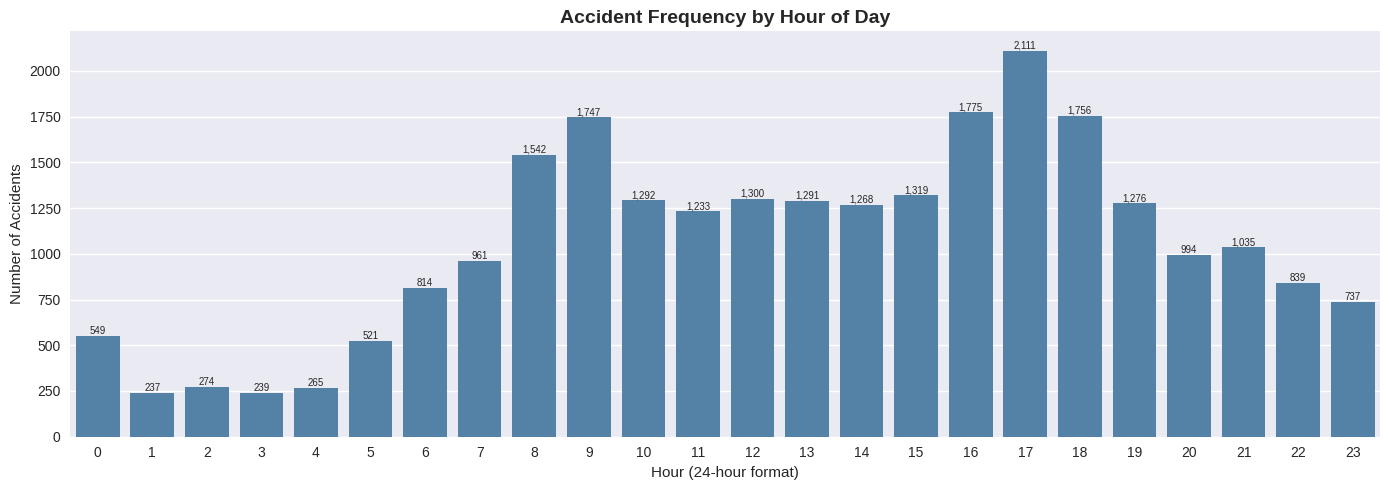

In [136]:
plt.figure(figsize=(14, 5))
ax = sns.countplot(data=df, x='hour', color='steelblue')
ax.set_title('Accident Frequency by Hour of Day')
ax.set_xlabel('Hour (24-hour format)')
ax.set_ylabel('Number of Accidents')
# Annotate bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=7)
plt.tight_layout()
plt.show()

## Time Period Classification

To simplify time-based analysis, individual hours were grouped into broader periods:

- Morning (5 AM – 11 AM)
- Afternoon (12 PM – 4 PM)
- Evening (5 PM – 8 PM)
- Night (9 PM – 4 AM)

This categorization helps identify broader accident trends throughout the day.

In [137]:
def get_time_period(hour):
    if 5<= hour < 12:
        return 'Morning'
    elif 12<= hour <17:
        return 'Afternoon'
    elif 17<= hour <21:
        return 'Evening'
    else:
        return 'Night'

In [138]:
df['time_period'] = df.hour.apply(get_time_period)

In [139]:
df.time_period.value_counts()


,count
time_period,
Morning,8110
Afternoon,6953
Evening,6137
Night,4175


/tmp/ipykernel_3534/2667122563.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='time_period', order=order, palette=colors)


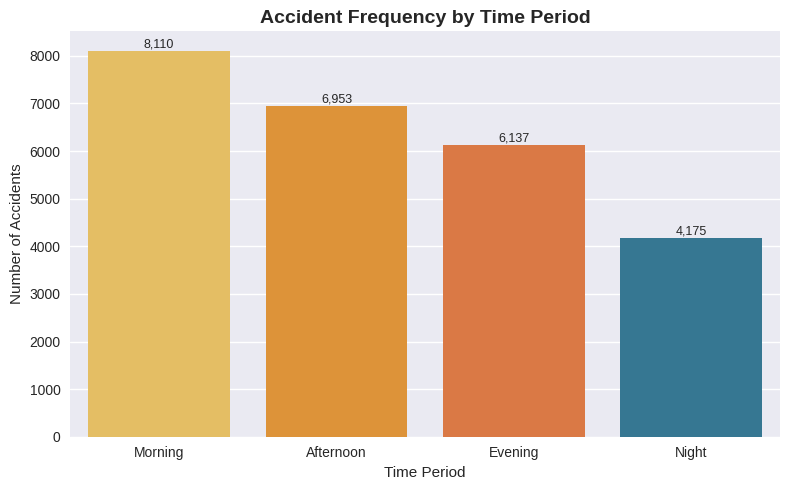

In [140]:
order = ['Morning', 'Afternoon', 'Evening', 'Night']
colors = ['#f9c74f', '#f8961e', '#f3722c', '#277da1']
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='time_period', order=order, palette=colors)
ax.set_title('Accident Frequency by Time Period')
ax.set_xlabel('Time Period')
ax.set_ylabel('Number of Accidents')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

## Day of Week Analysis

The day of occurrence was extracted from the accident date.

This feature helps identify whether accidents are evenly distributed across the week or concentrated on specific days.

In [141]:
df['day_of_week'] = pd.to_datetime(df.date).dt.day_name()

In [142]:
df.day_of_week.value_counts()

,count
day_of_week,
Tuesday,3695
Thursday,3688
Friday,3627
Wednesday,3622
Monday,3622
Sunday,3594
Saturday,3527


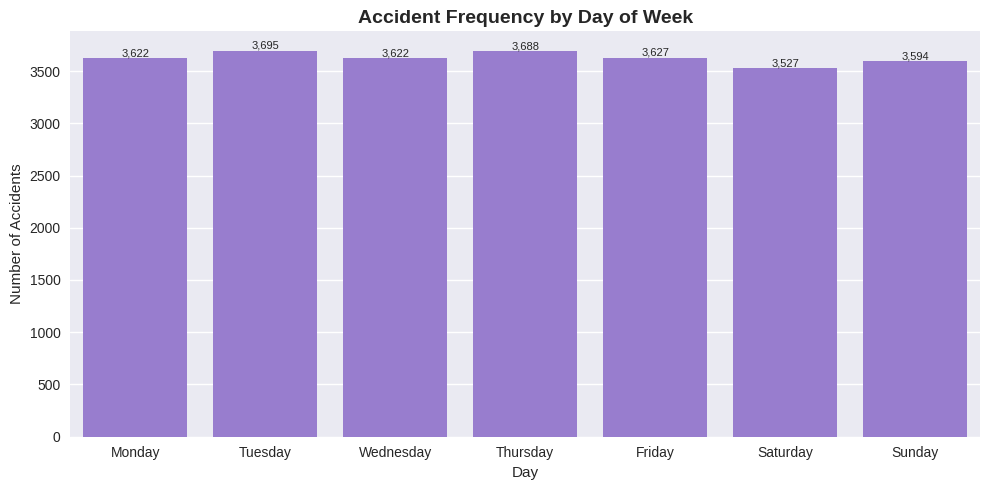

In [199]:
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
plt.figure(figsize=(10, 5))
ax = sns.countplot(data=df, x='day_of_week', order=day_order, color='mediumpurple')
ax.set_title('Accident Frequency by Day of Week')
ax.set_xlabel('Day')
ax.set_ylabel('Number of Accidents')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.show()

## Weekend Indicator

A binary feature was created to distinguish weekdays from weekends.

This allows comparison of accident patterns between regular working days and weekends.

In [144]:
df['is_weekend'] = df.day_of_week.isin(['Saturday','Sunday'])
df.is_weekend.value_counts()

,count
is_weekend,
False,18254
True,7121


# Exploratory Data Analysis (EDA)

## Univariate Analysis

Univariate analysis focuses on understanding the distribution of individual variables independently.

The objective is to identify:

- Most common accident severity levels
- Frequently involved vehicle types
- Major accident causes
- General patterns within the dataset

This analysis provides an initial understanding of accident characteristics before exploring relationships between variables.

## Accident Severity Distribution

Accident severity is the target variable of this analysis.

Understanding its distribution helps determine whether the dataset is balanced and provides insights into the overall seriousness of accidents.

/tmp/ipykernel_3534/744969304.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='accident_severity', order=sev_order, palette=sev_colors)


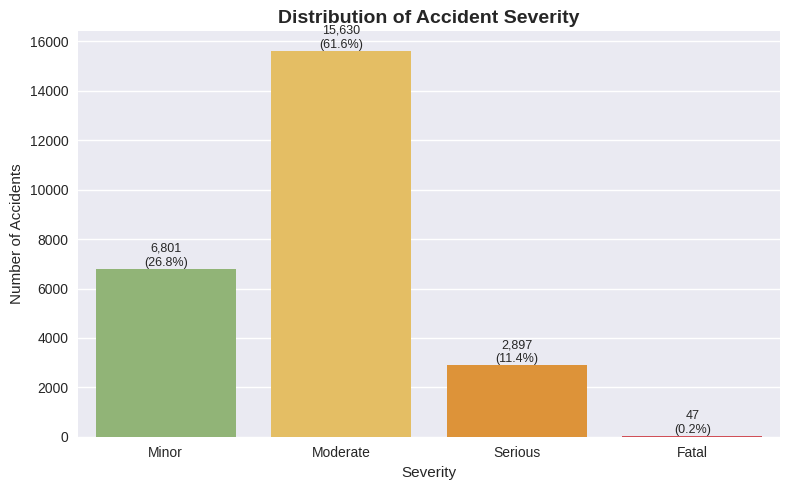

In [200]:
sev_order = ['Minor', 'Moderate', 'Serious', 'Fatal']
sev_colors = ['#90be6d', '#f9c74f', '#f8961e', '#e63946']
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='accident_severity', order=sev_order, palette=sev_colors)
ax.set_title('Distribution of Accident Severity')
ax.set_xlabel('Severity')
ax.set_ylabel('Number of Accidents')
total = len(df)
for p in ax.patches:
    pct = 100 * p.get_height() / total
    ax.annotate(f'{int(p.get_height()):,}\n({pct:.1f}%)',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

### Observation

- Moderate accidents represent the majority of incidents.
- Minor accidents form the second largest category.
- Serious accidents are comparatively less frequent.
- Fatal accidents are rare but highly important from a public safety perspective.

This indicates that while most accidents result in moderate damage, severe accidents still require focused investigation.

In [ ]:
df.accident_severity.value_counts(normalize= True)*100

## Vehicle Type Distribution

This analysis identifies which vehicle categories are most frequently involved in accidents.

Understanding vehicle participation helps identify vulnerable transportation groups and potential safety concerns.

In [ ]:
df.vehicle_type.value_counts()

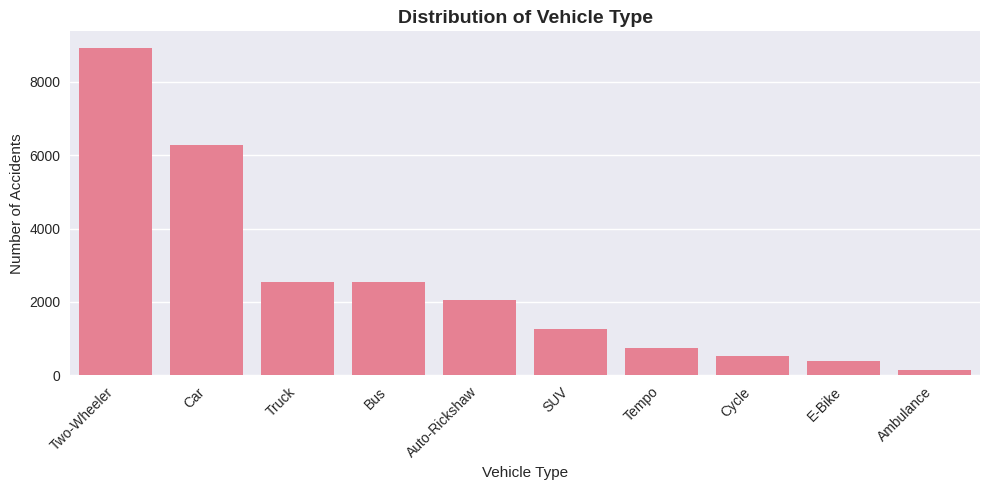

In [146]:
plt.figure(figsize=(10, 5))
ax = sns.countplot(data=df, x='vehicle_type',
                   order=df.vehicle_type.value_counts().index)
ax.set_title('Distribution of Vehicle Type')
ax.set_xlabel('Vehicle Type')
ax.set_ylabel('Number of Accidents')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

/tmp/ipykernel_3534/26687550.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=vehicle_counts.values, y=vehicle_counts.index, palette='viridis')


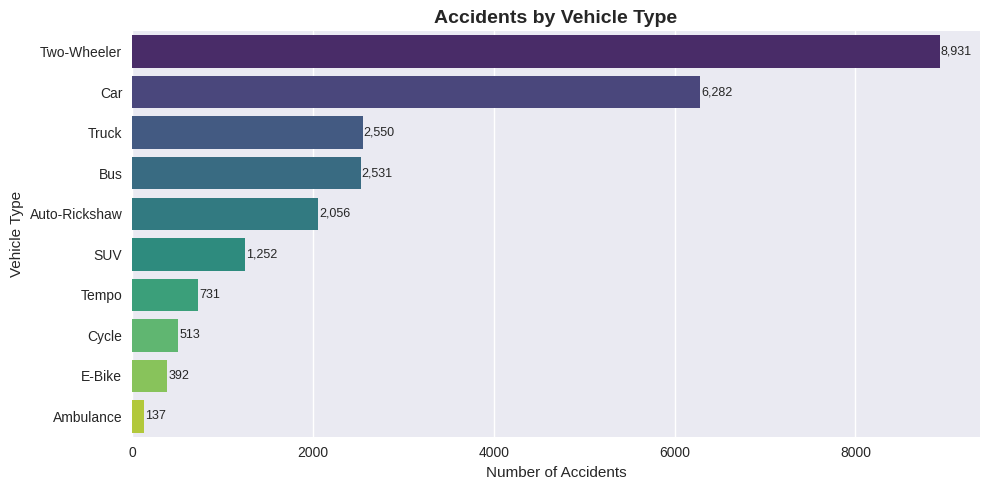

In [148]:
vehicle_counts = df.vehicle_type.value_counts()

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=vehicle_counts.values, y=vehicle_counts.index, palette='viridis')
ax.set_xlabel('Number of Accidents')
ax.set_ylabel('Vehicle Type')
ax.set_title('Accidents by Vehicle Type')
for i, v in enumerate(vehicle_counts.values):
    ax.text(v + 10, i, f'{v:,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

### Observation

- Two-Wheelers account for the highest number of accidents.
- Cars represent the second most common vehicle category.
- Trucks and buses contribute a moderate number of accidents.
- Ambulances and E-Bikes contribute very few accident cases.

The dominance of Two-Wheeler accidents highlights the need for targeted road safety measures for riders.

## Accident Cause Analysis

Understanding accident causes is essential for identifying preventable risk factors.

This analysis examines the most common reasons contributing to road accidents.

/tmp/ipykernel_3534/3559835226.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=cause_counts.values, y=cause_counts.index, palette='rocket')


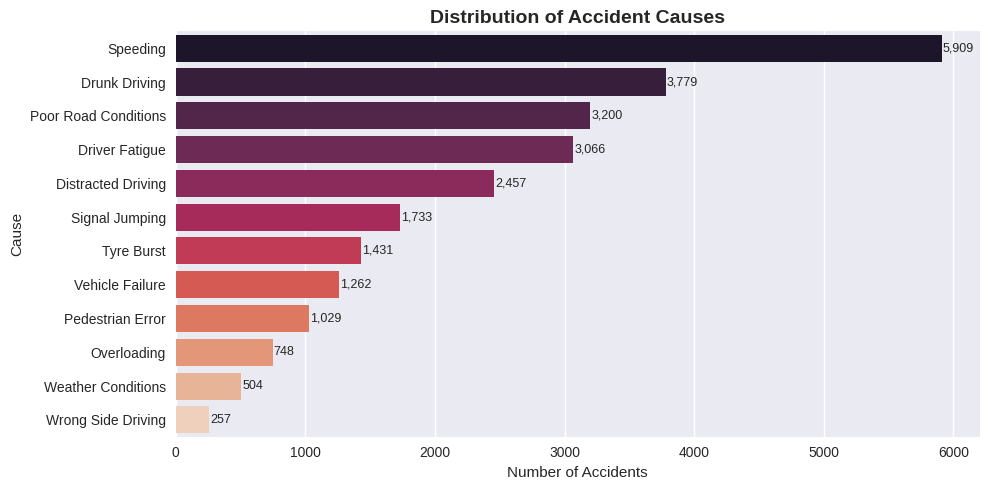

In [149]:
cause_counts = df.cause.value_counts()

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=cause_counts.values, y=cause_counts.index, palette='rocket')
ax.set_title('Distribution of Accident Causes')
ax.set_xlabel('Number of Accidents')
ax.set_ylabel('Cause')
for i, v in enumerate(cause_counts.values):
    ax.text(v + 10, i, f'{v:,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

### Observation

- Speeding is the most frequent cause of accidents.
- Drunk driving is the second most common cause.
- Poor road conditions and driver fatigue are also major contributors.
- Wrong-side driving and weather-related causes occur less frequently.

These findings suggest that driver behavior plays a significant role in accident occurrence.

## State-wise Accident Distribution

This analysis examines the geographical distribution of accidents across different states.

Understanding state-level accident patterns helps identify regions with higher accident frequencies and can support targeted road safety initiatives.

The top states with the highest accident counts are visualized below.

In [150]:
df.state.value_counts()

,count
state,
Uttar Pradesh,2417
Maharashtra,2064
Delhi,1834
Tamil Nadu,1592
Karnataka,1576
Gujarat,1445
West Bengal,1433
Rajasthan,1427
Andhra Pradesh,1426


/tmp/ipykernel_3534/2957037263.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=state_counts.values, y=state_counts.index, palette='Blues_r')


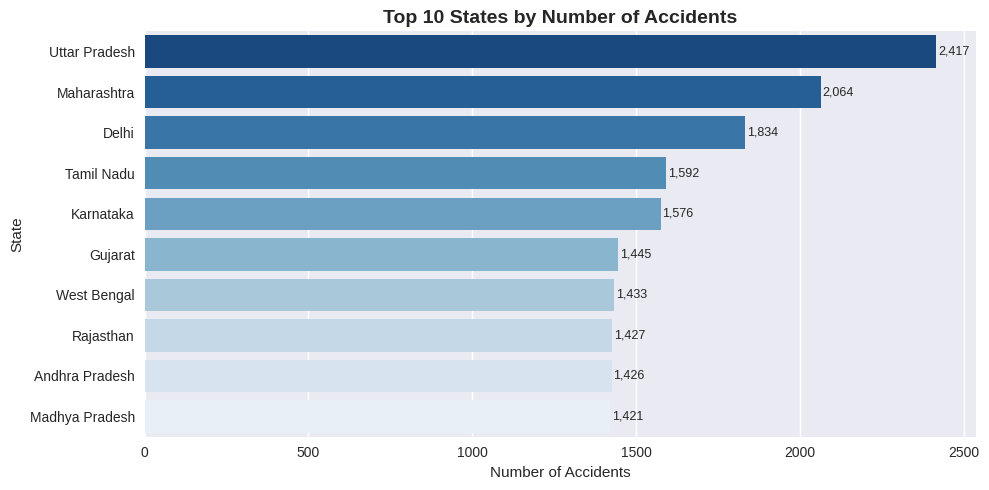

In [157]:
state_counts = df.state.value_counts().head(10)

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=state_counts.values, y=state_counts.index, palette='Blues_r')
ax.set_title('Top 10 States by Number of Accidents')
ax.set_xlabel('Number of Accidents')
ax.set_ylabel('State')
for i, v in enumerate(state_counts.values):
    ax.text(v + 5, i, f'{v:,}', va='center', fontsize=9)
plt.tight_layout()
#plt.savefig("../images/state_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

### Observation

- Uttar Pradesh recorded the highest number of accidents.
- Maharashtra and Delhi also contributed a significant share of total accidents.
- Accident occurrences are concentrated in a few highly populated states.

This suggests that traffic volume, population density, and road network size may influence accident frequency.

## City-wise Accident Distribution

City-level analysis provides a more detailed view of accident concentration within states.

The objective is to identify urban areas that experience a higher number of accidents and may require focused traffic management strategies.

In [152]:
df.city.value_counts().head(15)

,count
city,
Faridabad,508
Kanpur,370
Nashik,357
Meerut,356
Nagpur,356
Ghaziabad,350
Pune,349
Varanasi,349
Lucknow,340


/tmp/ipykernel_3534/3794038417.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=city_counts.values, y=city_counts.index, palette='Purples_r')


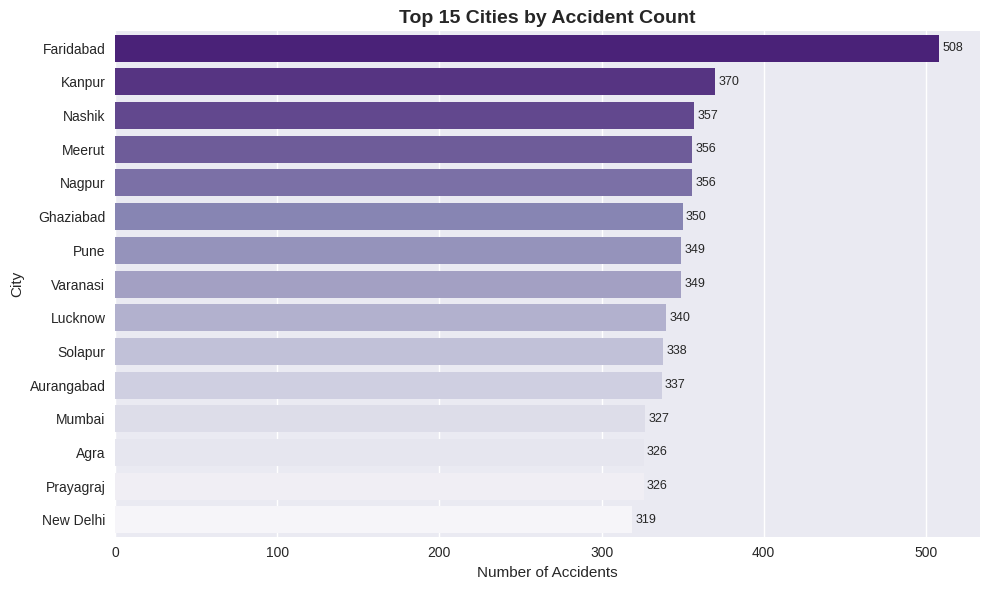

In [153]:
city_counts = df.city.value_counts().head(15)

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=city_counts.values, y=city_counts.index, palette='Purples_r')
ax.set_title('Top 15 Cities by Accident Count')
ax.set_xlabel('Number of Accidents')
ax.set_ylabel('City')
for i, v in enumerate(city_counts.values):
    ax.text(v + 2, i, f'{v:,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

### Observation

- Faridabad reported the highest number of accidents among all cities.
- Kanpur, Nashik, Meerut, and Nagpur also showed high accident frequencies.
- Accident counts are relatively concentrated among a small number of cities.

Urban traffic congestion and higher vehicle density may contribute to these patterns.

## Road Type Distribution

Road infrastructure plays a significant role in accident occurrence.

This analysis examines how accidents are distributed across different road types including Urban Roads, Rural Roads, and Highways.

In [154]:
df.road_type.value_counts()

,count
road_type,
Urban,11725
Rural,10658
Highw,2992


/tmp/ipykernel_3534/2953148435.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


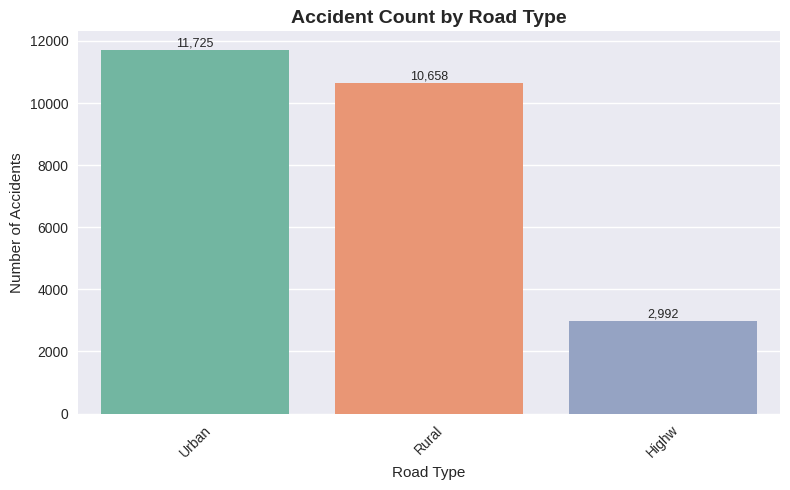

In [156]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(
    data=df, x='road_type',
    order=df.road_type.value_counts().index,
    palette='Set2'
)
ax.set_title('Accident Count by Road Type')
ax.set_xlabel('Road Type')
ax.set_ylabel('Number of Accidents')
plt.xticks(rotation=45)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.tight_layout()
#plt.savefig("../images/road_type_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

### Observation

- Urban roads account for the highest number of accidents.
- Rural roads contribute a comparable number of accidents.
- Highways have the lowest accident count among the three categories.

However, accident frequency alone does not indicate risk. Severity analysis is required to determine which road type is most dangerous.

# Bivariate Analysis

Bivariate analysis examines the relationship between two variables.

The objective is to understand which factors contribute to severe accidents rather than simply causing accidents.

High-risk accidents are defined as:

- Serious Accidents
- Fatal Accidents

## Relationship Between Accident Cause and Severity

Although some causes occur frequently, not all causes result in severe accidents.

This analysis identifies causes that have the highest probability of producing serious or fatal outcomes.

In [158]:
severity_risk = pd.crosstab(df.cause , df.accident_severity, normalize ='index')*100
severity_risk

accident_severity,Fatal,Minor,Moderate,Serious
cause,,,,
Distracted Driving,0.081400,34.920635,58.608059,6.389906
Driver Fatigue,0.489237,14.774951,72.504892,12.230920
Drunk Driving,0.317544,0.026462,66.313840,33.342154
Overloading,0.133690,33.689840,59.358289,6.818182
Pedestrian Error,0.291545,34.985423,56.948494,7.774538
Poor Road Conditions,0.062500,35.156250,58.250000,6.531250
Signal Jumping,0.057703,32.660127,61.396422,5.885747
Speeding,0.118463,34.015908,58.537824,7.327805
Tyre Burst,0.139762,34.311670,58.839972,6.708595


In [159]:
severity_risk['High_risk_%'] = (severity_risk.Fatal + severity_risk.Serious)
severity_risk['High_risk_%']

,High_risk_%
cause,
Distracted Driving,6.471306
Driver Fatigue,12.720157
Drunk Driving,33.659698
Overloading,6.951872
Pedestrian Error,8.066084
Poor Road Conditions,6.593750
Signal Jumping,5.943451
Speeding,7.446268
Tyre Burst,6.848358


In [160]:
severity_risk = severity_risk.sort_values('High_risk_%', ascending= False)
severity_risk

accident_severity,Fatal,Minor,Moderate,Serious,High_risk_%
cause,,,,,
Drunk Driving,0.317544,0.026462,66.313840,33.342154,33.659698
Driver Fatigue,0.489237,14.774951,72.504892,12.230920,12.720157
Pedestrian Error,0.291545,34.985423,56.948494,7.774538,8.066084
Speeding,0.118463,34.015908,58.537824,7.327805,7.446268
Wrong Side Driving,0.389105,36.575875,56.031128,7.003891,7.392996
Weather Conditions,0.000000,31.944444,60.714286,7.341270,7.341270
Overloading,0.133690,33.689840,59.358289,6.818182,6.951872
Tyre Burst,0.139762,34.311670,58.839972,6.708595,6.848358
Poor Road Conditions,0.062500,35.156250,58.250000,6.531250,6.593750


/tmp/ipykernel_3534/4131024677.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=severity_risk['High_risk_%'], y=severity_risk.index, palette='Reds_r')


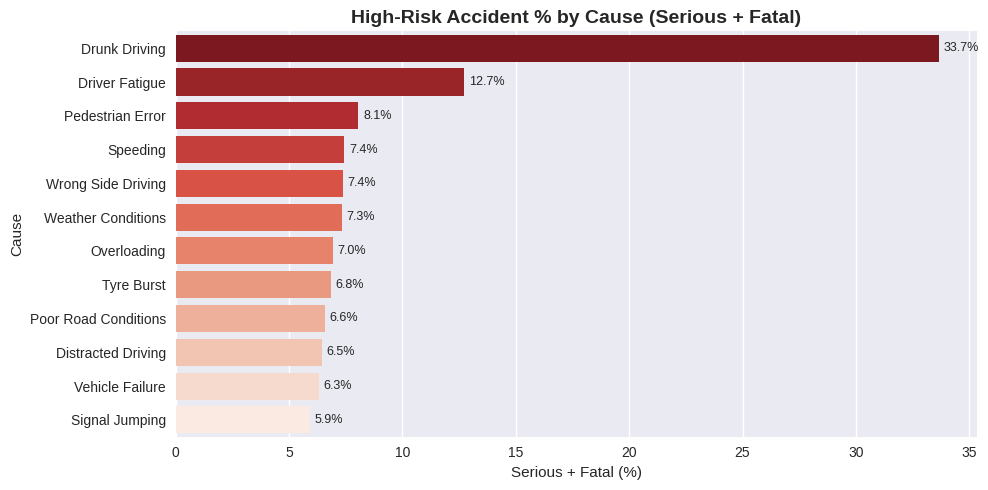

In [161]:
plt.figure(figsize=(10, 5))
ax = sns.barplot(x=severity_risk['High_risk_%'], y=severity_risk.index, palette='Reds_r')
ax.set_title('High-Risk Accident % by Cause (Serious + Fatal)')
ax.set_xlabel('Serious + Fatal (%)')
ax.set_ylabel('Cause')
for i, v in enumerate(severity_risk['High_risk_%']):
    ax.text(v + 0.2, i, f'{v:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.show()

### Observation

- Drunk Driving has the highest proportion of serious and fatal accidents.
- Driver Fatigue ranks second in severity risk.
- Speeding causes many accidents, but its severity risk is lower than drunk driving.
- Signal Jumping and Vehicle Failure show comparatively lower severity percentages.

These findings indicate that accident frequency and accident severity are not always the same.

## Alcohol Involvement and Accident Severity

Alcohol consumption is widely recognized as a major road safety risk factor.

This analysis investigates how accident severity changes when alcohol is involved.

In [162]:
pd.crosstab(df.alcohol_involved,df.accident_severity,normalize= 'index')*100

accident_severity,Fatal,Minor,Moderate,Serious
alcohol_involved,,,,
False,0.000000,36.522346,61.339708,2.137946
True,0.695369,0.029590,62.302116,36.972925


In [163]:
alcohol_severity = pd.crosstab(df.alcohol_involved,df.accident_severity,normalize= 'index')*100
alcohol_severity

accident_severity,Fatal,Minor,Moderate,Serious
alcohol_involved,,,,
False,0.000000,36.522346,61.339708,2.137946
True,0.695369,0.029590,62.302116,36.972925


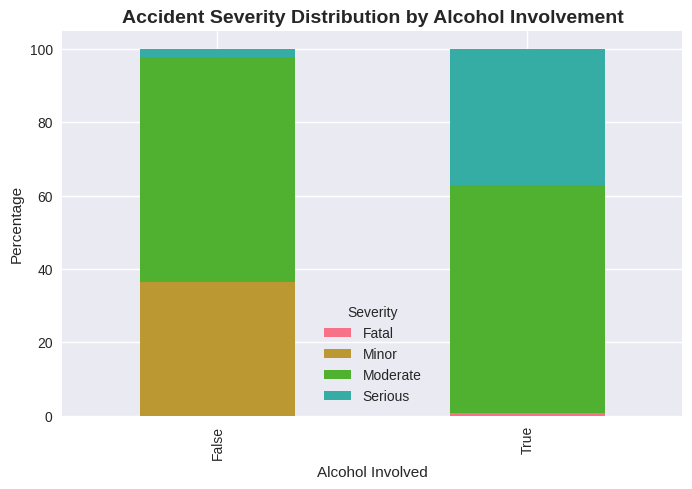

In [201]:
alcohol_severity.plot(kind = 'bar', stacked = True,figsize = (8,5))
plt.title('Accident Severity Distribution by Alcohol Involvement')
plt.ylabel('Percentage')
plt.xlabel('Alcohol Involved')
plt.legend(title='Severity')
plt.show()

### Observation

- Accidents involving alcohol show a significantly higher proportion of serious and fatal outcomes.
- Non-alcohol-related accidents are primarily classified as minor or moderate.
- Serious accidents increase dramatically when alcohol is involved.

This confirms alcohol involvement as one of the strongest indicators of accident severity.

In [166]:
round(alcohol_severity, 2)

accident_severity,Fatal,Minor,Moderate,Serious
alcohol_involved,,,,
False,0.0,36.52,61.34,2.14
True,0.7,0.03,62.30,36.97


## Vehicle Type and Accident Severity

Different vehicle categories provide varying levels of protection to occupants.

This analysis investigates whether certain vehicle types are associated with higher severity accidents.

In [167]:
vehicle_severity = pd.crosstab(df.vehicle_type, df.accident_severity,normalize='index')*100
vehicle_severity

accident_severity,Fatal,Minor,Moderate,Serious
vehicle_type,,,,
Ambulance,0.000000,19.708029,67.883212,12.408759
Auto-Rickshaw,0.097276,27.772374,61.138132,10.992218
Bus,0.237060,27.301462,61.793757,10.667720
Car,0.191022,26.201847,62.082139,11.524992
Cycle,0.000000,27.290448,64.132554,8.576998
E-Bike,0.255102,25.255102,64.540816,9.948980
SUV,0.239617,28.194888,59.424920,12.140575
Tempo,0.410397,26.402189,63.337893,9.849521
Truck,0.078431,27.137255,60.588235,12.196078


In [168]:
vehicle_severity['high_risk_%'] = (vehicle_severity.Fatal + vehicle_severity.Serious)
vehicle_severity

accident_severity,Fatal,Minor,Moderate,Serious,high_risk_%
vehicle_type,,,,,
Ambulance,0.000000,19.708029,67.883212,12.408759,12.408759
Auto-Rickshaw,0.097276,27.772374,61.138132,10.992218,11.089494
Bus,0.237060,27.301462,61.793757,10.667720,10.904781
Car,0.191022,26.201847,62.082139,11.524992,11.716014
Cycle,0.000000,27.290448,64.132554,8.576998,8.576998
E-Bike,0.255102,25.255102,64.540816,9.948980,10.204082
SUV,0.239617,28.194888,59.424920,12.140575,12.380192
Tempo,0.410397,26.402189,63.337893,9.849521,10.259918
Truck,0.078431,27.137255,60.588235,12.196078,12.274510


In [169]:
vehicle_severity = vehicle_severity.sort_values('high_risk_%', ascending= False)
vehicle_severity

accident_severity,Fatal,Minor,Moderate,Serious,high_risk_%
vehicle_type,,,,,
Ambulance,0.000000,19.708029,67.883212,12.408759,12.408759
SUV,0.239617,28.194888,59.424920,12.140575,12.380192
Truck,0.078431,27.137255,60.588235,12.196078,12.274510
Two-Wheeler,0.201545,26.749524,61.381704,11.667227,11.868772
Car,0.191022,26.201847,62.082139,11.524992,11.716014
Auto-Rickshaw,0.097276,27.772374,61.138132,10.992218,11.089494
Bus,0.237060,27.301462,61.793757,10.667720,10.904781
Tempo,0.410397,26.402189,63.337893,9.849521,10.259918
E-Bike,0.255102,25.255102,64.540816,9.948980,10.204082


/tmp/ipykernel_3534/1087753263.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=vehicle_severity['high_risk_%'], y=vehicle_severity.index, palette='Oranges_r')


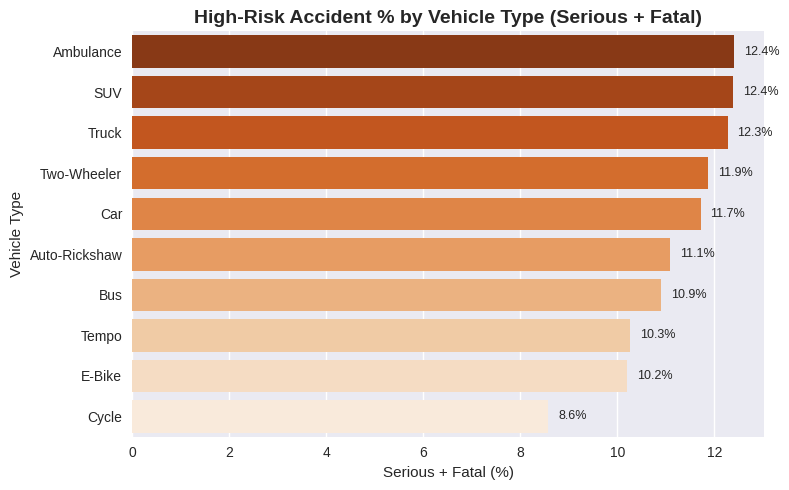

In [170]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=vehicle_severity['high_risk_%'], y=vehicle_severity.index, palette='Oranges_r')
ax.set_title('High-Risk Accident % by Vehicle Type (Serious + Fatal)')
ax.set_xlabel('Serious + Fatal (%)')
ax.set_ylabel('Vehicle Type')
for i, v in enumerate(vehicle_severity['high_risk_%']):
    ax.text(v + 0.2, i, f'{v:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.show()

### Observation

- SUVs, Trucks, and Two-Wheelers show relatively higher severity percentages.
- Cars and Auto-Rickshaws exhibit moderate severity levels.
- Cycles have the lowest proportion of severe accidents.

Vehicle design, speed capability, and occupant protection may influence accident outcomes.

## Weather Condition and Accident Severity

Weather conditions affect visibility, road grip, and driver reaction time.

This analysis evaluates how different weather situations influence accident severity.

In [171]:
pd.crosstab(df.weather_condition,df.accident_severity,normalize= 'index')*100

accident_severity,Fatal,Minor,Moderate,Serious
weather_condition,,,,
Clear,0.000000,45.864962,50.659209,3.475829
Cloudy,0.000000,43.506261,53.094812,3.398927
Foggy,0.247866,3.607822,75.268521,20.875792
Haze,0.000000,45.703704,51.444444,2.851852
Rainy,0.547196,1.778386,74.589603,23.084815
Stormy,0.552486,1.657459,74.769797,23.020258
Sunny,0.000000,43.305931,52.583676,4.110393


In [172]:
weather_risk = pd.crosstab(
    df['weather_condition'],
    df['accident_severity'],
    normalize='index'
) * 100

weather_risk['High_Risk_%'] = (
    weather_risk['Serious']
    + weather_risk['Fatal']
)

weather_risk = weather_risk.sort_values(
    'High_Risk_%',
    ascending=False
)

/tmp/ipykernel_3534/3456446214.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=weather_risk['High_Risk_%'], y=weather_risk.index, palette='coolwarm')


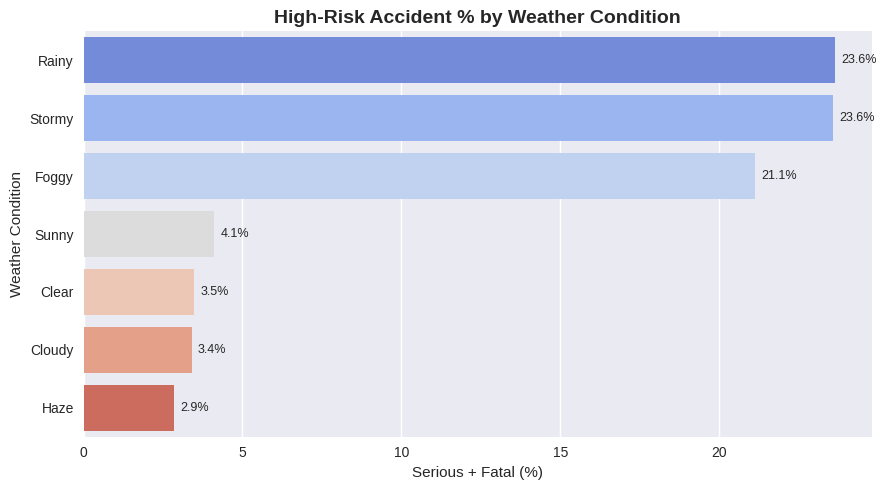

In [175]:
plt.figure(figsize=(9, 5))
ax = sns.barplot(x=weather_risk['High_Risk_%'], y=weather_risk.index, palette='coolwarm')
ax.set_title('High-Risk Accident % by Weather Condition')
ax.set_xlabel('Serious + Fatal (%)')
ax.set_ylabel('Weather Condition')
for i, v in enumerate(weather_risk['High_Risk_%']):
    ax.text(v + 0.2, i, f'{v:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.show()

### Observation

- Rainy and Stormy weather conditions show the highest severity risk.
- Foggy conditions also contribute substantially to severe accidents.
- Clear, Sunny, and Cloudy weather exhibit lower severity percentages.

Adverse weather conditions significantly increase accident risk and severity.

## Road Type and Accident Severity

While urban roads experience more accidents, the severity of accidents may vary across road types.

This analysis evaluates the percentage of high-risk accidents (Serious + Fatal) associated with each road category.

In [176]:
road_severity = pd.crosstab(
    df.road_type,
    df.accident_severity,
    normalize='index'
)*100

road_severity['High_Risk_%'] = (
    road_severity['Fatal']
    + road_severity['Serious']
)

road_severity = road_severity.sort_values(
    'High_Risk_%',
    ascending=False
)

road_severity

accident_severity,Fatal,Minor,Moderate,Serious,High_Risk_%
road_type,,,,,
Highw,0.133690,23.729947,62.967914,13.168449,13.302139
Rural,0.290861,24.179020,62.760368,12.769750,13.060612
Urban,0.102345,29.970149,60.187633,9.739872,9.842217


/tmp/ipykernel_3534/4026063607.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=road_severity['High_Risk_%'], y=road_severity.index, palette='Set1')


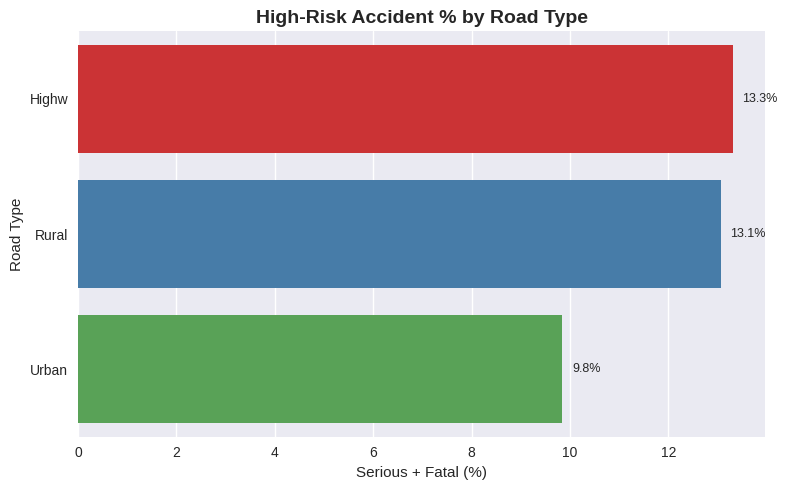

In [177]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=road_severity['High_Risk_%'], y=road_severity.index, palette='Set1')
ax.set_title('High-Risk Accident % by Road Type')
ax.set_xlabel('Serious + Fatal (%)')
ax.set_ylabel('Road Type')
for i, v in enumerate(road_severity['High_Risk_%']):
    ax.text(v + 0.2, i, f'{v:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.show()

### Observation

- Highways exhibit the highest percentage of serious and fatal accidents.
- Rural roads show a similar severity pattern.
- Urban roads experience more accidents overall but a lower proportion of severe accidents.

This suggests that higher travel speeds on highways and rural roads increase the likelihood of severe accident outcomes.

## State-wise High-Risk Accident Analysis

Accident frequency alone does not fully capture road safety conditions.

This analysis focuses on the proportion of high-risk accidents (Serious + Fatal) across states to identify regions with greater accident severity.

In [178]:
state_severity = pd.crosstab(
    df.state,
    df.accident_severity,
    normalize='index'
)*100

state_severity['High_Risk_%'] = (
    state_severity['Fatal']
    + state_severity['Serious']
)

state_severity = state_severity.sort_values(
    'High_Risk_%',
    ascending=False
)

state_severity[['High_Risk_%']].head(10)

accident_severity,High_Risk_%
state,
Odisha,13.400759
Tamil Nadu,13.379397
Jharkhand,12.960000
Madhya Pradesh,12.526390
Assam,12.409639
Andhra Pradesh,12.272090
Uttar Pradesh,12.122466
Karnataka,12.119289
Uttarakhand,12.038523


/tmp/ipykernel_3534/1864444367.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


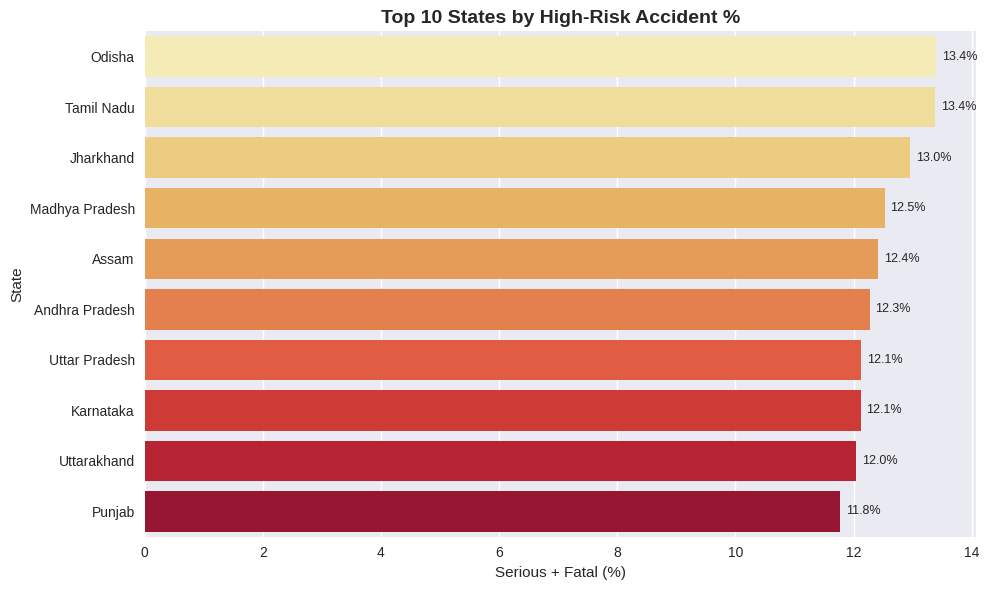

In [179]:
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x=state_severity.head(10)['High_Risk_%'],
    y=state_severity.head(10).index,
    palette='YlOrRd'
)
ax.set_title('Top 10 States by High-Risk Accident %')
ax.set_xlabel('Serious + Fatal (%)')
ax.set_ylabel('State')
for i, v in enumerate(state_severity.head(10)['High_Risk_%']):
    ax.text(v + 0.1, i, f'{v:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.show()

### Observation

- Odisha and Tamil Nadu recorded the highest percentages of high-risk accidents.
- Several states with moderate accident counts still exhibited elevated severity levels.
- Accident severity varies significantly across states.

These findings indicate that accident risk is influenced not only by accident frequency but also by factors such as road conditions, driving behavior, and emergency response effectiveness.

In [180]:
num_cols = [
    'speed_limit',
    'number_of_vehicles',
    'number_of_injuries',
    'number_of_deaths',
    'driver_age',
    'emergency_response_time'
]


# Numerical Feature Correlation Analysis

Correlation analysis measures the strength of linear relationships between numerical variables.

The correlation coefficient ranges from:

- +1 : Strong positive relationship
- 0 : No relationship
- -1 : Strong negative relationship

This analysis helps identify potential dependencies among numerical features.

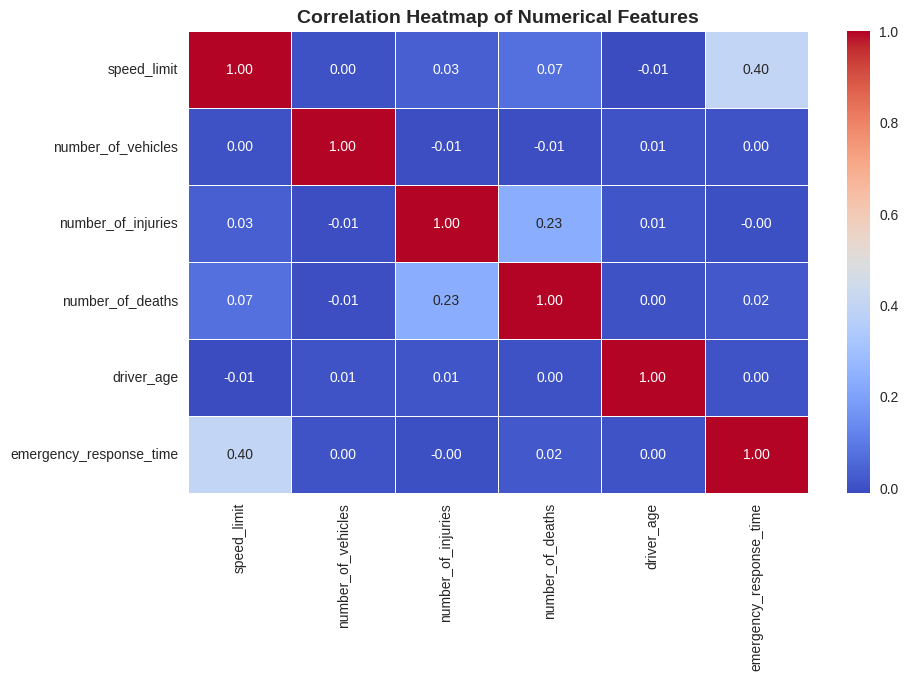

In [183]:

plt.figure(figsize=(10,6))

sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Features')
plt.show()

### Observation

- Most numerical variables show weak correlations with each other.
- Speed Limit and Emergency Response Time exhibit a moderate positive relationship.
- Number of Injuries and Number of Deaths display a mild positive correlation.
- No strong multicollinearity is present among numerical variables.

This suggests that each feature contributes unique information to the dataset.

# Multivariate Analysis

Multivariate analysis examines the interaction among three or more variables simultaneously.

Unlike univariate and bivariate analysis, this approach helps uncover complex patterns that may not be visible when analyzing variables individually.

The objective is to identify how multiple factors jointly influence accident severity and injury outcomes.

## Weather Condition, Accident Severity and Injuries

This analysis investigates how weather conditions and accident severity together affect the average number of injuries.

A pivot table and heatmap are used to identify combinations associated with higher injury counts.

In [184]:
pivot_weather = pd.pivot_table(
    df,
    values='number_of_injuries',
    index='weather_condition',
    columns='accident_severity',
    aggfunc='mean'
)

pivot_weather

accident_severity,Fatal,Minor,Moderate,Serious
weather_condition,,,,
Clear,NaN,1.732578,2.705836,4.114943
Cloudy,NaN,1.794408,2.632749,4.115789
Foggy,6.888889,1.648855,2.638492,4.427441
Haze,NaN,1.696921,2.689705,4.285714
Rainy,6.312500,1.817308,2.623796,4.305926
Stormy,6.500000,1.444444,2.689655,4.364000
Sunny,NaN,1.740000,2.651591,4.475000


In [185]:
pivot_time = pd.pivot_table(
    df,
    values='number_of_injuries',
    index='time_period',
    columns='accident_severity',
    aggfunc='mean'
)

pivot_time

accident_severity,Fatal,Minor,Moderate,Serious
time_period,,,,
Afternoon,NaN,1.730050,2.649861,4.407895
Evening,6.500000,1.671396,2.627299,4.303226
Morning,7.000000,1.788082,2.680938,4.469173
Night,6.351351,1.791667,2.622472,4.275087


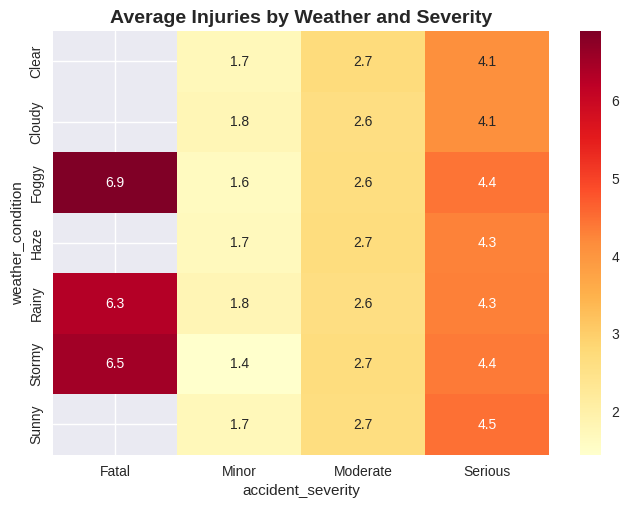

In [186]:
multi = pd.pivot_table(
    df,
    values='number_of_injuries',
    index='weather_condition',
    columns='accident_severity',
    aggfunc='mean'
)

sns.heatmap(
    multi,
    annot=True,
    cmap='YlOrRd',
    fmt='.1f'
)

plt.title('Average Injuries by Weather and Severity')
plt.show()

### Observation

- Fatal accidents consistently show the highest average number of injuries.
- Rainy, Stormy and Foggy weather conditions tend to be associated with more severe injury outcomes.
- Serious accidents generally result in more injuries than minor or moderate accidents regardless of weather condition.

This suggests that adverse weather conditions amplify accident consequences.

## Combined Effect of Time Period and Alcohol Involvement

This analysis explores how alcohol involvement and time of day jointly influence accident severity.

The goal is to identify high-risk combinations that contribute to serious accidents.

In [ ]:
multi1 = pd.crosstab(
    [df['time_period'], df['alcohol_involved']],
    df['accident_severity'],
    normalize='index'
) * 100

plt.figure(figsize=(8,5))

sns.heatmap(
    multi1[['Serious']],
    annot=True,
    fmt='.1f',
    cmap='Reds'
)

plt.title('Serious Accident Percentage by Time Period and Alcohol Involvement')
plt.show()

### Observation

- Night-time accidents involving alcohol exhibit the highest proportion of serious accidents.
- Evening and Morning accidents involving alcohol also show elevated severity levels.
- When alcohol is not involved, serious accident percentages remain relatively low across all time periods.

This highlights the combined impact of impaired driving and reduced nighttime visibility.

# Statistical Validation — Chi-Square Test

To statistically confirm whether the observed relationship between accident cause and severity is significant, a **Chi-Square Test of Independence** was performed.

**Hypothesis:**
- H₀ (Null): Accident cause and accident severity are independent (no relationship)
- H₁ (Alternative): Accident cause and accident severity are significantly related

A p-value below 0.05 indicates that the relationship is statistically significant and not due to chance.

In [187]:
from scipy.stats import chi2_contingency

# Test 1: Cause vs Severity
ct_cause = pd.crosstab(df['cause'], df['accident_severity'])
chi2_cause, p_cause, dof_cause, _ = chi2_contingency(ct_cause)

# Test 2: Alcohol vs Severity
ct_alcohol = pd.crosstab(df['alcohol_involved'], df['accident_severity'])
chi2_alc, p_alc, dof_alc, _ = chi2_contingency(ct_alcohol)

# Test 3: Weather vs Severity
ct_weather = pd.crosstab(df['weather_condition'], df['accident_severity'])
chi2_wea, p_wea, dof_wea, _ = chi2_contingency(ct_weather)

# Test 4: Road Type vs Severity
ct_road = pd.crosstab(df['road_type'], df['accident_severity'])
chi2_road, p_road, dof_road, _ = chi2_contingency(ct_road)

results = pd.DataFrame({
    'Variables Tested': [
        'Cause vs Severity',
        'Alcohol Involvement vs Severity',
        'Weather Condition vs Severity',
        'Road Type vs Severity'
    ],
    'Chi-Square Statistic': [chi2_cause, chi2_alc, chi2_wea, chi2_road],
    'Degrees of Freedom': [dof_cause, dof_alc, dof_wea, dof_road],
    'p-value': [p_cause, p_alc, p_wea, p_road],
    'Significant (p<0.05)': [
        'Yes' if p < 0.05 else 'No'
        for p in [p_cause, p_alc, p_wea, p_road]
    ]
})

results['Chi-Square Statistic'] = results['Chi-Square Statistic'].round(2)
results['p-value'] = results['p-value'].apply(lambda x: f'{x:.4f}' if x >= 0.0001 else '< 0.0001')
print(results.to_string(index=False))

               Variables Tested  Chi-Square Statistic  Degrees of Freedom  p-value Significant (p<0.05)
              Cause vs Severity               3635.47                  33 < 0.0001                  Yes
Alcohol Involvement vs Severity               7864.51                   3 < 0.0001                  Yes
  Weather Condition vs Severity               6526.44                  18 < 0.0001                  Yes
          Road Type vs Severity                154.05                   6 < 0.0001                  Yes


### Observation

All four relationships tested returned a **p-value < 0.05**, which means we **reject the null hypothesis** in every case.

This statistically confirms that:
- Accident cause is significantly associated with accident severity
- Alcohol involvement significantly affects outcome severity
- Weather conditions have a statistically significant impact on severity
- Road type is significantly related to accident severity

These findings are not due to chance — the patterns observed in the EDA are statistically valid.

# Summary — Key Risk Factors at a Glance

The table below consolidates the most important findings from the analysis, comparing accident frequency against severity risk for the top factors identified.

In [188]:
# Build summary comparison table
summary_data = {
    'Factor': [
        'Drunk Driving', 'Driver Fatigue', 'Speeding',
        'Signal Jumping', 'Wrong-Side Driving',
        'Highway Roads', 'Rural Roads', 'Urban Roads',
        'Rainy / Stormy Weather', 'Clear Weather',
        'Two-Wheelers', 'SUVs / Trucks'
    ],
    'Category': [
        'Cause', 'Cause', 'Cause', 'Cause', 'Cause',
        'Road Type', 'Road Type', 'Road Type',
        'Weather', 'Weather',
        'Vehicle', 'Vehicle'
    ],
    'Accident Frequency': [
        '2nd Highest', 'Moderate', 'Highest',
        'Low', 'Low',
        'Lowest', 'Moderate', 'Highest',
        'Moderate', 'High',
        'Highest', 'Moderate'
    ],
    'Severity Risk': [
        'HIGHEST', 'High', 'Moderate',
        'Low', 'Low',
        'HIGHEST', 'High', 'Moderate',
        'HIGHEST', 'Low',
        'High', 'High'
    ],
    'Key Insight': [
        'Deadliest cause despite lower frequency than speeding',
        'Underreported but highly dangerous',
        'Most frequent cause — enforcement priority',
        'Common but less severe',
        'Dangerous but infrequent',
        'Higher speeds → worse outcomes',
        'Similar severity risk to highways',
        'Volume hub, moderate severity',
        'Adverse weather amplifies outcomes',
        'Safe conditions, lower risk',
        'Most accidents, significant severity',
        'Less frequent, higher severity'
    ]
}

summary_df = pd.DataFrame(summary_data)

def color_severity(val):
    color_map = {
        'HIGHEST': 'background-color: #e63946; color: white; font-weight: bold',
        'High': 'background-color: #f8961e; color: white',
        'Moderate': 'background-color: #f9c74f',
        'Low': 'background-color: #90be6d',
    }
    return color_map.get(val, '')

summary_df.style.applymap(color_severity, subset=['Severity Risk'])

/tmp/ipykernel_3534/4009278305.py:57: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  summary_df.style.applymap(color_severity, subset=['Severity Risk'])


,Factor,Category,Accident Frequency,Severity Risk,Key Insight
0,Drunk Driving,Cause,2nd Highest,HIGHEST,Deadliest cause despite lower frequency than speeding
1,Driver Fatigue,Cause,Moderate,High,Underreported but highly dangerous
2,Speeding,Cause,Highest,Moderate,Most frequent cause — enforcement priority
3,Signal Jumping,Cause,Low,Low,Common but less severe
4,Wrong-Side Driving,Cause,Low,Low,Dangerous but infrequent
5,Highway Roads,Road Type,Lowest,HIGHEST,Higher speeds → worse outcomes
6,Rural Roads,Road Type,Moderate,High,Similar severity risk to highways
7,Urban Roads,Road Type,Highest,Moderate,"Volume hub, moderate severity"
8,Rainy / Stormy Weather,Weather,Moderate,HIGHEST,Adverse weather amplifies outcomes
9,Clear Weather,Weather,High,Low,"Safe conditions, lower risk"


# Conclusion

This project analyzed road accident data to identify the factors influencing accident occurrence and severity across different environmental, geographical, vehicular, and human-related dimensions.

## Key Findings

### Accident Characteristics

* Moderate accidents accounted for the majority of reported cases.
* Serious accidents represented a significant portion of total accidents.
* Fatal accidents were comparatively rare but carried the highest impact.

### Vehicle Analysis

* Two-Wheelers were involved in the highest number of accidents, followed by Cars.
* SUVs, Trucks, and Two-Wheelers showed relatively higher proportions of serious and fatal accidents.
* Vehicle type influences accident severity, although the differences were moderate.

### Human Factors

* Speeding was the most frequent cause of accidents.
* Drunk Driving exhibited the highest probability of resulting in serious or fatal accidents.
* Driver Fatigue was identified as another major contributor to severe accidents.
* Alcohol involvement significantly increased accident severity, particularly during night-time periods.

### Environmental Factors

* Rainy, Stormy, and Foggy weather conditions were associated with higher accident severity.
* Adverse weather conditions resulted in higher average injury counts and increased accident risk.

### Geographical Analysis

* Uttar Pradesh recorded the highest number of accidents, followed by Maharashtra and Delhi.
* Faridabad reported the highest accident count among cities in the dataset.
* States such as Odisha and Tamil Nadu exhibited the highest proportions of serious and fatal accidents, indicating elevated accident risk despite not necessarily having the highest accident frequency.

### Road Infrastructure Analysis

* Urban roads accounted for the largest share of accidents.
* Highways and Rural roads showed higher proportions of serious and fatal accidents compared to Urban roads.
* Higher travel speeds on highways appear to contribute to increased accident severity.

### Temporal Patterns

* Morning and Afternoon periods recorded the highest accident frequencies.
* Night-time accidents involving alcohol demonstrated the greatest severity risk.
* Time of occurrence plays an important role in accident outcomes.

### Data Insights

* Correlation analysis revealed generally weak relationships among numerical variables.
* Speed Limit showed a moderate positive relationship with Emergency Response Time.
* Detected outliers represented meaningful real-world accident scenarios and were retained to preserve valuable information.

## Overall Conclusion

The analysis indicates that human behavioral factors, particularly drunk driving, speeding, and driver fatigue, are the strongest contributors to severe road accidents. Environmental conditions such as rain, fog, and storms further increase accident severity, while highways and rural roads present greater risks of serious outcomes due to higher operating speeds.

Geographical analysis revealed substantial variation in accident frequency and severity across states and cities, suggesting that local infrastructure, traffic conditions, and safety enforcement practices influence accident outcomes.

These findings can support policymakers, traffic authorities, and road safety organizations in developing targeted interventions focused on driver behavior, alcohol control measures, weather-related safety awareness, and high-risk road segments to reduce accident severity and improve public safety.
